# RNG variation in graspologic SGM

This short diagnostic asks whether graspologic's randomized tie handling changes SGM's result for the **same graph pair and seed set**. It compares:

- **Sparse ER (current experiment):** (n=600, p=0.01, \rho=0.7, k=26), using the saved fixed pair.
- **Dense ER (literature-style):** (n=300, p=0.5, \rho=0.6, k=6). The 2014 correlated-ER study used (n=300, p=0.5) and varied (\rho) and the number of seeds. The particular (\rho=0.6,k=6) point is a small transition-regime diagnostic, rather than a parameter recommendation from that paper.

For each of three random seed sets, the notebook calls the public `graspologic.match.graph_match` function five times with `n_init=1` and different RNG seeds. It then reports the result of choosing the best objective among those five runs, which is the decision rule used by `n_init=5`.

The first-step instrumentation uses graspologic's private solver methods only to **observe** the gradient, LAP direction, and line-search step. The matching itself is still performed by graspologic. This notebook expects graspologic 3.4.4, the version used by the project.

Local references:

- [Seeded Graph Matching](../Literature%20Review/1209.0367v4.pdf)
- [Seeded Graph Matching for Correlated Erdős-Rényi Graphs (2014)](../Literature%20Review/lyzinski14a.pdf)

This is intentionally a diagnostic, not an estimate of population-level variance. Increase `N_SEED_SETS` only if the short run reveals something worth confirming.

In [1]:
import os
import sys
import math
import tempfile
import time
import warnings
from contextlib import contextmanager
from dataclasses import replace
from importlib.metadata import version
from itertools import combinations
from pathlib import Path

os.environ.setdefault("NUMBA_CACHE_DIR", str(Path(tempfile.gettempdir()) / "sgm_numba_cache"))
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "sgm_matplotlib_cache"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse.csgraph import connected_components


def find_repo_root(start):
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "experiment_common").exists() and (candidate / "research_notes").exists():
            return candidate
    raise FileNotFoundError("Could not find the Seeded-Graph-Matching repository root.")


ROOT = find_repo_root(Path.cwd())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from graspologic.match import graph_match
import graspologic.match.wrappers as match_wrappers
from experiment_common.graphs import generate_graph_pair, preset_config

GRASPOLOGIC_VERSION = version("graspologic")
print("Repository:", ROOT)
print("graspologic:", GRASPOLOGIC_VERSION)

if not hasattr(match_wrappers, "_GraphMatchSolver"):
    raise ImportError("This diagnostic requires graspologic's _GraphMatchSolver instrumentation hook.")
if GRASPOLOGIC_VERSION != "3.4.4":
    warnings.warn(
        "This notebook was validated with graspologic 3.4.4. "
        "Check the instrumentation if the private solver API has changed."
    )

Matplotlib is building the font cache; this may take a moment.


Repository: /Users/langsong/Desktop/Seeded-Graph-Matching
graspologic: 3.4.4


## 1. Settings and graph pairs

The sparse case loads the exact fixed graph pair used by the current ER experiments. The dense case is generated once with a fixed seed. Graph B is randomly relabeled in both cases, and `true_permutation[i]` gives the observed Graph-B label corresponding to Graph-A vertex (i).

In [2]:
N_SEED_SETS = 3
SGM_RNG_SEEDS = [2026, 2027, 2028, 2029, 2030]
SEED_SET_RNG = 20261012
SUCCESS_THRESHOLD = 0.90
MAX_ITER = 100
TOL = 0.01

SPARSE_K = 26
DENSE_K = 6
DENSE_PAIR_SEED = 8675309

sparse_path = (
    ROOT
    / "fixed_pair_seed_set_classification"
    / "data"
    / "sgm_multi_rng"
    / "graph_pairs"
    / "sparse_er_problem.npz"
)
if not sparse_path.exists():
    raise FileNotFoundError(f"Missing saved sparse pair: {sparse_path}")

with np.load(sparse_path) as saved:
    sparse_A = saved["adjacency_graph1"].astype(float)
    sparse_B = saved["adjacency_graph2"].astype(float)
    sparse_truth = saved["true_permutation"].astype(int)

dense_config = replace(
    preset_config("sparse_er"),
    vertex_count=300,
    er_probability=0.5,
    rho=0.6,
    n_seeds=DENSE_K,
    max_iter=MAX_ITER,
    tol=TOL,
)
dense_A, dense_B, dense_truth = generate_graph_pair(dense_config, DENSE_PAIR_SEED)

cases = {
    "Sparse ER": {
        "A": sparse_A,
        "B": sparse_B,
        "truth": sparse_truth,
        "n": 600,
        "p": 0.01,
        "rho": 0.7,
        "k": SPARSE_K,
    },
    "Dense ER": {
        "A": dense_A,
        "B": dense_B,
        "truth": dense_truth,
        "n": 300,
        "p": 0.5,
        "rho": 0.6,
        "k": DENSE_K,
    },
}

seed_rng = np.random.default_rng(SEED_SET_RNG)
for case in cases.values():
    case["seed_sets"] = [
        np.sort(seed_rng.choice(case["n"], size=case["k"], replace=False))
        for _ in range(N_SEED_SETS)
    ]


def graph_pair_summary(name, case):
    A, B, truth = case["A"], case["B"], case["truth"]
    aligned_B = B[np.ix_(truth, truth)]
    upper = np.triu_indices_from(A, k=1)
    return {
        "setting": name,
        "n": len(A),
        "p": case["p"],
        "rho_target": case["rho"],
        "k": case["k"],
        "mean_degree_A": A.sum(axis=1).mean(),
        "max_degree_A": A.sum(axis=1).max(),
        "components_A": connected_components(A, directed=False, return_labels=False),
        "components_B": connected_components(B, directed=False, return_labels=False),
        "observed_edge_correlation": np.corrcoef(A[upper], aligned_B[upper])[0, 1],
    }


settings_table = pd.DataFrame(
    [graph_pair_summary(name, case) for name, case in cases.items()]
).set_index("setting")
display(settings_table.round(3))

,n,p,rho_target,k,mean_degree_A,max_degree_A,components_A,components_B,observed_edge_correlation
setting,,,,,,,,,
Sparse ER,600,0.01,0.7,26,5.917,13.0,5,1,0.689
Dense ER,300,0.50,0.6,6,149.300,172.0,1,1,0.603


## 2. Observe the first Frank-Wolfe step

For each run, graspologic starts from the barycenter, calculates the first gradient, and solves a linear assignment problem (LAP). Its solver randomly permutes the LAP rows before calling SciPy because SciPy otherwise resolves ties according to input order.

The diagnostics below record:

- the fraction of unseeded vertices belonging to an **exactly identical gradient-row group**;
- the largest such group;
- a conservative lower bound on the number of equally scoring LAP solutions obtained by permuting assignments within identical-row groups;
- how much the first assignments differ across RNG seeds;
- the fraction of the first line-search update that moves toward the selected permutation (Q).

The lower bound does not enumerate every optimal LAP solution. Aggregate assignment ties can also exist without identical rows, so it should be interpreted as a guaranteed minimum caused by this particular tie mechanism.

In [3]:
@contextmanager
def capture_first_frank_wolfe_step():
    Solver = match_wrappers._GraphMatchSolver
    original_gradient = Solver.compute_gradient
    original_direction = Solver.compute_step_direction
    original_step_size = Solver.compute_step_size
    captured = {}

    def wrapped_gradient(solver, P):
        gradient = original_gradient(solver, P)
        if "gradient" not in captured:
            captured["solver"] = solver
            captured["P"] = np.asarray(P).copy()
            captured["gradient"] = np.asarray(gradient).copy()
        return gradient

    def wrapped_direction(solver, gradient, rng):
        Q = original_direction(solver, gradient, rng)
        if "Q" not in captured:
            captured["Q"] = np.asarray(Q).copy()
        return Q

    def wrapped_step_size(solver, P, Q):
        alpha = original_step_size(solver, P, Q)
        if "alpha" not in captured:
            captured["alpha"] = float(alpha)
        return alpha

    Solver.compute_gradient = wrapped_gradient
    Solver.compute_step_direction = wrapped_direction
    Solver.compute_step_size = wrapped_step_size
    try:
        yield captured
    finally:
        Solver.compute_gradient = original_gradient
        Solver.compute_step_direction = original_direction
        Solver.compute_step_size = original_step_size


def identical_group_summary(matrix, axis=0):
    values = matrix if axis == 0 else matrix.T
    counts = np.unique(values, axis=0, return_counts=True)[1]
    tied_sizes = np.sort(counts[counts > 1])[::-1]
    n_items = values.shape[0]
    tied_items = int(tied_sizes.sum()) if len(tied_sizes) else 0
    log10_lower_bound = float(
        sum(math.lgamma(int(size) + 1) for size in tied_sizes) / math.log(10)
    )
    return {
        "n_tied_groups": int(len(tied_sizes)),
        "n_items_in_tied_groups": tied_items,
        "tied_fraction": tied_items / n_items,
        "largest_tied_group": int(tied_sizes[0]) if len(tied_sizes) else 1,
        "largest_groups": ", ".join(map(str, tied_sizes[:8])) if len(tied_sizes) else "none",
        "log10_factorial_lower_bound": log10_lower_bound,
    }


def run_instrumented_sgm(A, B, truth, seeds_A, rng_seed):
    seeds_A = np.sort(np.asarray(seeds_A, dtype=int))
    seeds_B = truth[seeds_A]
    partial_match = np.column_stack((seeds_A, seeds_B))

    started = time.perf_counter()
    with capture_first_frank_wolfe_step() as captured:
        result = graph_match(
            A,
            B,
            partial_match=partial_match,
            init=None,
            init_perturbation=0.0,
            n_init=1,
            shuffle_input=True,
            maximize=True,
            n_jobs=1,
            max_iter=MAX_ITER,
            tol=TOL,
            rng=int(rng_seed),
        )
    runtime = time.perf_counter() - started

    required = {"solver", "gradient", "Q", "alpha"}
    missing = required.difference(captured)
    if missing:
        raise RuntimeError(f"Did not capture first-step fields: {sorted(missing)}")

    solver = captured["solver"]
    gradient = captured["gradient"]
    Q = captured["Q"]
    first_assignment = np.argmax(Q, axis=1)

    unseeded_A = np.asarray(solver.perm_A[solver.n_seeds :], dtype=int)
    unseeded_B = np.asarray(solver.perm_B[solver.n_seeds :], dtype=int)
    first_prediction = unseeded_B[first_assignment]
    first_accuracy = np.mean(first_prediction == truth[unseeded_A])

    final_permutation = np.full(len(A), -1, dtype=int)
    final_permutation[result.indices_A] = result.indices_B
    final_accuracy = np.mean(final_permutation[unseeded_A] == truth[unseeded_A])

    row_ties = identical_group_summary(gradient, axis=0)
    column_ties = identical_group_summary(gradient, axis=1)

    seed_neighbors_A = A[np.ix_(unseeded_A, seeds_A)].sum(axis=1)
    seed_neighbors_B = B[np.ix_(unseeded_B, seeds_B)].sum(axis=1)

    return {
        "rng_seed": int(rng_seed),
        "runtime_seconds": runtime,
        "final_unseeded_accuracy": float(final_accuracy),
        "success": bool(final_accuracy >= SUCCESS_THRESHOLD),
        "objective": float(result.score),
        "n_iter": int(result.misc[0]["n_iter"]),
        "converged": bool(result.misc[0]["converged"]),
        "first_direction_accuracy": float(first_accuracy),
        "first_lap_score": float(np.sum(gradient * Q)),
        # graspologic uses P_new = alpha*P + (1-alpha)*Q.
        "first_move_fraction_to_Q": float(1 - captured["alpha"]),
        "first_assignment": tuple(map(int, first_assignment)),
        "no_seed_neighbor_fraction_A": float(np.mean(seed_neighbors_A == 0)),
        "no_seed_neighbor_fraction_B": float(np.mean(seed_neighbors_B == 0)),
        "exact_tied_row_fraction": row_ties["tied_fraction"],
        "exact_tied_row_groups": row_ties["n_tied_groups"],
        "largest_exact_row_group": row_ties["largest_tied_group"],
        "largest_exact_row_groups": row_ties["largest_groups"],
        "log10_guaranteed_lap_optima": row_ties["log10_factorial_lower_bound"],
        "exact_tied_column_fraction": column_ties["tied_fraction"],
        "largest_exact_column_group": column_ties["largest_tied_group"],
    }

## 3. Run the diagnostic

With the defaults, this performs 30 SGM runs. On the project machine it should take roughly a minute or less after imports and compilation caches are warm. The five runs for a particular seed set differ only in graspologic's `rng` argument.

In [4]:
records = []
diagnostic_started = time.perf_counter()

for setting, case in cases.items():
    for seed_set_id, seeds_A in enumerate(case["seed_sets"]):
        for run_id, rng_seed in enumerate(SGM_RNG_SEEDS):
            result = run_instrumented_sgm(
                case["A"], case["B"], case["truth"], seeds_A, rng_seed
            )
            result.update(
                {
                    "setting": setting,
                    "seed_set_id": seed_set_id,
                    "run_id": run_id,
                    "n": case["n"],
                    "p": case["p"],
                    "rho": case["rho"],
                    "k": case["k"],
                    "seed_vertices": tuple(map(int, seeds_A)),
                }
            )
            records.append(result)
        print(f"Finished {setting}, seed set {seed_set_id + 1}/{N_SEED_SETS}")

runs = pd.DataFrame(records)
elapsed = time.perf_counter() - diagnostic_started
print(f"Completed {len(runs)} SGM runs in {elapsed:.1f} seconds.")
display(
    runs[
        [
            "setting",
            "seed_set_id",
            "run_id",
            "rng_seed",
            "first_direction_accuracy",
            "first_move_fraction_to_Q",
            "final_unseeded_accuracy",
            "success",
            "objective",
            "n_iter",
        ]
    ].round(3)
)

Finished Sparse ER, seed set 1/3
Finished Sparse ER, seed set 2/3
Finished Sparse ER, seed set 3/3
Finished Dense ER, seed set 1/3
Finished Dense ER, seed set 2/3
Finished Dense ER, seed set 3/3
Completed 30 SGM runs in 27.6 seconds.


,setting,seed_set_id,run_id,rng_seed,first_direction_accuracy,first_move_fraction_to_Q,final_unseeded_accuracy,success,objective,n_iter
0,Sparse ER,0,0,2026,0.071,1.0,0.336,False,1666.0,48
1,Sparse ER,0,1,2027,0.075,1.0,0.960,True,2458.0,27
2,Sparse ER,0,2,2028,0.070,1.0,0.251,False,1572.0,38
3,Sparse ER,0,3,2029,0.070,1.0,0.949,True,2454.0,100
4,Sparse ER,0,4,2030,0.077,1.0,0.282,False,1608.0,42
5,Sparse ER,1,0,2026,0.063,1.0,0.176,False,1512.0,32
6,Sparse ER,1,1,2027,0.061,1.0,0.960,True,2460.0,84
7,Sparse ER,1,2,2028,0.061,1.0,0.164,False,1502.0,25
8,Sparse ER,1,3,2029,0.063,1.0,0.148,False,1482.0,26
9,Sparse ER,1,4,2030,0.066,1.0,0.220,False,1556.0,33


## 4. How much does RNG change the result?

The next table summarizes variation for each fixed seed set. `distinct_first_assignments` counts how many different first LAP directions appeared among the five RNG seeds. `mean_pairwise_first_disagreement` is the average fraction of unseeded assignments that differ between two first directions. A mixed success label means the same seed set both passed and failed the 0.90 threshold.

,setting,seed_set_id,accuracy_mean,accuracy_sd,accuracy_min,accuracy_max,success_fraction,mixed_success_label,objective_range,distinct_first_assignments,mean_pairwise_first_disagreement,same_first_lap_score
0,Sparse ER,0,0.556,0.327,0.251,0.960,0.4,True,886.0,5,0.857,True
1,Sparse ER,1,0.333,0.314,0.148,0.960,0.2,True,978.0,5,0.832,True
2,Sparse ER,2,0.499,0.383,0.152,0.969,0.4,True,980.0,5,0.848,True
3,Dense ER,0,0.251,0.375,0.058,1.000,0.2,True,8868.0,5,0.166,True
4,Dense ER,1,0.819,0.362,0.095,1.000,0.8,True,8694.0,5,0.124,True
5,Dense ER,2,0.029,0.006,0.020,0.037,0.0,False,140.0,5,0.143,True


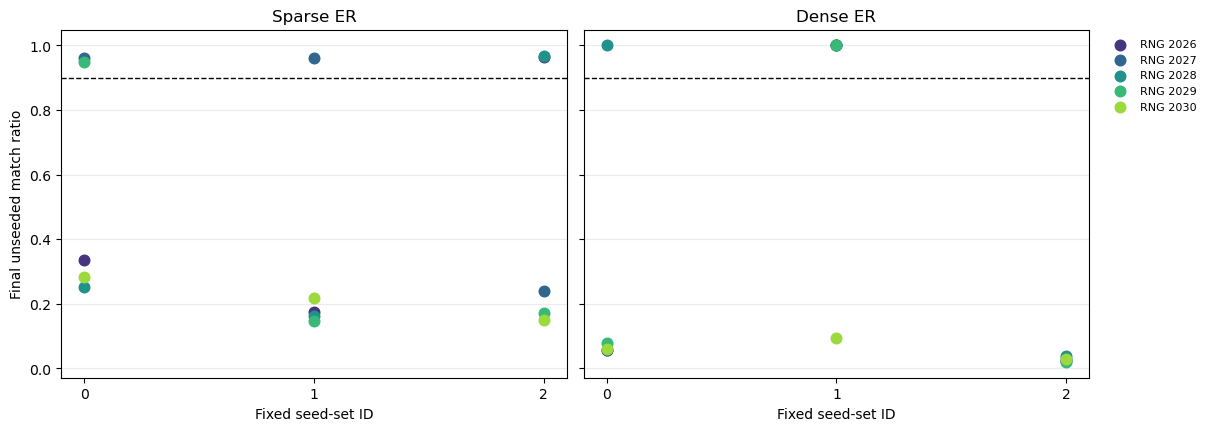

In [5]:
def assignment_variation(group):
    assignments = [np.asarray(x, dtype=int) for x in group["first_assignment"]]
    distances = [
        np.mean(left != right)
        for left, right in combinations(assignments, 2)
    ]
    return pd.Series(
        {
            "accuracy_mean": group["final_unseeded_accuracy"].mean(),
            "accuracy_sd": group["final_unseeded_accuracy"].std(ddof=0),
            "accuracy_min": group["final_unseeded_accuracy"].min(),
            "accuracy_max": group["final_unseeded_accuracy"].max(),
            "success_fraction": group["success"].mean(),
            "mixed_success_label": group["success"].nunique() > 1,
            "objective_range": group["objective"].max() - group["objective"].min(),
            "distinct_first_assignments": len(set(group["first_assignment"])),
            "mean_pairwise_first_disagreement": np.mean(distances),
            "same_first_lap_score": np.ptp(group["first_lap_score"].to_numpy()) < 1e-8,
        }
    )


set_summary = (
    runs.groupby(["setting", "seed_set_id"], sort=False)
    .apply(assignment_variation, include_groups=False)
    .reset_index()
)
display(set_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True, constrained_layout=True)
colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(SGM_RNG_SEEDS)))

for axis, (setting, group) in zip(axes, runs.groupby("setting", sort=False)):
    for run_id, run_group in group.groupby("run_id"):
        axis.scatter(
            run_group["seed_set_id"],
            run_group["final_unseeded_accuracy"],
            s=58,
            color=colors[int(run_id)],
            label=f"RNG {SGM_RNG_SEEDS[int(run_id)]}",
            zorder=3,
        )
    axis.axhline(SUCCESS_THRESHOLD, color="black", linestyle="--", linewidth=1)
    axis.set_title(setting)
    axis.set_xlabel("Fixed seed-set ID")
    axis.set_xticks(range(N_SEED_SETS))
    axis.grid(axis="y", alpha=0.25)

axes[0].set_ylabel("Final unseeded match ratio")
axes[1].legend(frameon=False, fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

## 5. What ties are visible in the first LAP?

These quantities depend on the graph pair and seed set but not on the RNG tie-break, so one row per seed set is enough. `log10_guaranteed_lap_optima` is the base-10 logarithm of the lower bound: a value of 100 means that identical gradient rows alone guarantee at least (10^{100}) equally scoring first-step assignments.

In [6]:
tie_columns = [
    "setting",
    "seed_set_id",
    "no_seed_neighbor_fraction_A",
    "no_seed_neighbor_fraction_B",
    "exact_tied_row_fraction",
    "exact_tied_row_groups",
    "largest_exact_row_group",
    "largest_exact_row_groups",
    "exact_tied_column_fraction",
    "largest_exact_column_group",
    "log10_guaranteed_lap_optima",
    "first_move_fraction_to_Q",
]
tie_table = runs.loc[runs["run_id"].eq(0), tie_columns].copy()
display(tie_table.round(3))

tie_setting_summary = (
    tie_table.groupby("setting", sort=False)
    .agg(
        no_seed_neighbor_fraction_A=("no_seed_neighbor_fraction_A", "mean"),
        exact_tied_row_fraction=("exact_tied_row_fraction", "mean"),
        largest_exact_row_group=("largest_exact_row_group", "max"),
        log10_guaranteed_lap_optima=("log10_guaranteed_lap_optima", "mean"),
        first_move_fraction_to_Q=("first_move_fraction_to_Q", "mean"),
    )
)
display(tie_setting_summary.round(3))

,setting,seed_set_id,no_seed_neighbor_fraction_A,no_seed_neighbor_fraction_B,exact_tied_row_fraction,exact_tied_row_groups,largest_exact_row_group,largest_exact_row_groups,exact_tied_column_fraction,largest_exact_column_group,log10_guaranteed_lap_optima,first_move_fraction_to_Q
0,Sparse ER,0,0.756,0.767,0.829,35,63,"63, 59, 54, 45, 42, 37, 26, 24",0.819,58,506.970,1.0
5,Sparse ER,1,0.772,0.760,0.822,31,61,"61, 59, 52, 46, 42, 39, 31, 26",0.805,62,513.508,1.0
10,Sparse ER,2,0.763,0.768,0.821,34,68,"68, 62, 53, 44, 39, 36, 27, 27",0.834,60,510.045,1.0
15,Dense ER,0,0.031,0.014,0.133,19,3,"3, 2, 2, 2, 2, 2, 2, 2",0.143,2,6.197,1.0
20,Dense ER,1,0.010,0.017,0.136,20,2,"2, 2, 2, 2, 2, 2, 2, 2",0.133,3,6.021,1.0
25,Dense ER,2,0.017,0.024,0.133,19,3,"3, 2, 2, 2, 2, 2, 2, 2",0.092,3,6.197,1.0


,no_seed_neighbor_fraction_A,exact_tied_row_fraction,largest_exact_row_group,log10_guaranteed_lap_optima,first_move_fraction_to_Q
setting,,,,,
Sparse ER,0.764,0.824,68,510.174,1.0
Dense ER,0.019,0.134,3,6.138,1.0


## 6. One run versus keeping the best objective among five

`single_*` uses the first RNG seed only. `best5_*` selects, for each fixed seed set, the run with the largest graspologic objective among the five explicit runs. This reproduces the substantive comparison behind `n_init=1` versus `n_init=5` while retaining all five individual outcomes for inspection.

,setting,seed_set_id,single_accuracy,best5_accuracy,single_success,best5_success,single_objective,best5_objective,best5_rng_seed,accuracy_gain,success_label_changed
0,Dense ER,0,0.058,1.000,False,True,27046.0,35882.0,2028,0.942,True
1,Dense ER,1,1.000,1.000,True,True,35882.0,35882.0,2026,0.000,False
2,Dense ER,2,0.024,0.031,False,False,26980.0,27112.0,2027,0.007,False
3,Sparse ER,0,0.336,0.960,False,True,1666.0,2458.0,2027,0.624,True
4,Sparse ER,1,0.176,0.960,False,True,1512.0,2460.0,2027,0.784,True
5,Sparse ER,2,0.963,0.963,True,True,2460.0,2460.0,2026,0.000,False


,seed_sets,single_success_rate,best5_success_rate,single_mean_accuracy,best5_mean_accuracy,mean_accuracy_gain,changed_success_labels
setting,,,,,,,
Dense ER,3,0.333,0.667,0.361,0.677,0.316,1
Sparse ER,3,0.333,1.000,0.492,0.961,0.469,2


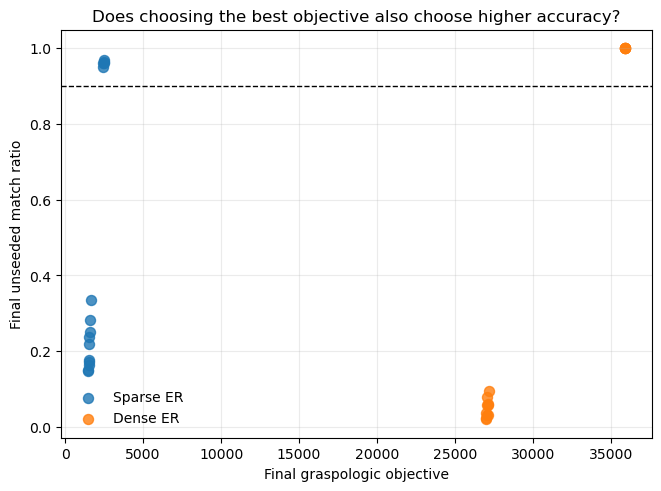

,objective_accuracy_correlation
setting,
Sparse ER,0.999
Dense ER,0.999


In [7]:
single = runs.loc[runs["run_id"].eq(0)].set_index(["setting", "seed_set_id"])
best_index = runs.groupby(["setting", "seed_set_id"])["objective"].idxmax()
best5 = runs.loc[best_index].set_index(["setting", "seed_set_id"])

comparison = pd.DataFrame(
    {
        "single_accuracy": single["final_unseeded_accuracy"],
        "best5_accuracy": best5["final_unseeded_accuracy"],
        "single_success": single["success"],
        "best5_success": best5["success"],
        "single_objective": single["objective"],
        "best5_objective": best5["objective"],
        "best5_rng_seed": best5["rng_seed"],
    }
).reset_index()
comparison["accuracy_gain"] = comparison["best5_accuracy"] - comparison["single_accuracy"]
comparison["success_label_changed"] = comparison["single_success"] != comparison["best5_success"]
display(comparison.round(3))

comparison_summary = comparison.groupby("setting", sort=False).agg(
    seed_sets=("seed_set_id", "size"),
    single_success_rate=("single_success", "mean"),
    best5_success_rate=("best5_success", "mean"),
    single_mean_accuracy=("single_accuracy", "mean"),
    best5_mean_accuracy=("best5_accuracy", "mean"),
    mean_accuracy_gain=("accuracy_gain", "mean"),
    changed_success_labels=("success_label_changed", "sum"),
)
display(comparison_summary.round(3))

fig, axis = plt.subplots(figsize=(6.5, 4.8), constrained_layout=True)
for setting, group in runs.groupby("setting", sort=False):
    axis.scatter(group["objective"], group["final_unseeded_accuracy"], s=52, alpha=0.8, label=setting)
axis.axhline(SUCCESS_THRESHOLD, color="black", linestyle="--", linewidth=1)
axis.set_xlabel("Final graspologic objective")
axis.set_ylabel("Final unseeded match ratio")
axis.set_title("Does choosing the best objective also choose higher accuracy?")
axis.grid(alpha=0.25)
axis.legend(frameon=False)
plt.show()

objective_accuracy_correlation = runs.groupby("setting", sort=False).apply(
    lambda x: x["objective"].corr(x["final_unseeded_accuracy"]),
    include_groups=False,
).rename("objective_accuracy_correlation")
display(objective_accuracy_correlation.to_frame().round(3))

## 7. Separate within-seed-set variation from between-set variation

For equally repeated seed sets, the total variance can be decomposed into:

\[
\operatorname{Var}(Y)=
\operatorname{Var}_S\{E(Y\mid S)\}
+E_S\{\operatorname{Var}(Y\mid S)\}.
\]

The first term is variation attributable to the choice of seed set; the second is variation across graspologic RNG seeds for a fixed seed set. With only three sets and five runs, these are descriptive diagnostics rather than precise variance estimates.

In [8]:
def variance_decomposition(group, outcome):
    by_set = group.groupby("seed_set_id")[outcome]
    set_means = by_set.mean()
    between = float(set_means.var(ddof=0))
    within = float(by_set.var(ddof=0).mean())
    total = between + within
    return pd.Series(
        {
            "between_seed_set_variance": between,
            "within_seed_set_rng_variance": within,
            "within_rng_share": within / total if total > 0 else np.nan,
        }
    )


variance_rows = []
for setting, group in runs.groupby("setting", sort=False):
    for outcome in ["final_unseeded_accuracy", "success"]:
        values = variance_decomposition(group, outcome)
        variance_rows.append({"setting": setting, "outcome": outcome, **values.to_dict()})

variance_table = pd.DataFrame(variance_rows).set_index(["setting", "outcome"])
display(variance_table.round(4))

between_seed_set_variance  \
setting   outcome                                              
Sparse ER final_unseeded_accuracy                     0.0089   
          success                                     0.0089   
Dense ER  final_unseeded_accuracy                     0.1108   
          success                                     0.1156   

                                   within_seed_set_rng_variance  \
setting   outcome                                                 
Sparse ER final_unseeded_accuracy                        0.1173   
          success                                        0.2133   
Dense ER  final_unseeded_accuracy                        0.0904   
          success                                        0.1067   

                                   within_rng_share  
setting   outcome                                    
Sparse ER final_unseeded_accuracy            0.9296  
          success                            0.9600  
Dense ER  final_unseeded_accuracy            0.4495  
          success                            0.4800

## Reading the diagnostic

- **Sparse has many more exact tied rows, but dense outcomes are stable:** sparsity is creating the expected first-step degeneracy, and the dense setting is a useful primary control.
- **Both settings vary near their transition:** tie-breaking sensitivity is not exclusive to sparse graphs; proximity to an algorithmic success/failure boundary also matters.
- **The first LAP score is constant while its assignments differ:** graspologic is selecting different equally scoring first directions.
- **The first assignments differ but final outcomes agree:** later Frank-Wolfe iterations are correcting harmless early ambiguity.
- **The best objective consistently has the best accuracy:** `n_init=5` is a defensible practical solver variant, but it should be named explicitly because it is a different procedure from single-initialization SGM.
- **Objective and accuracy disagree:** selecting by objective is not reliably selecting the true correspondence in that regime.

The useful target for subsequent calibration is an overall mixture of stable successful and stable unsuccessful seed sets: large between-set variation and small within-set RNG variation. An overall 50% success rate by itself is insufficient if most individual seed sets flip across runs.